Install required libraries

In [9]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn

Import libraries

In [10]:
import pandas as pd
import numpy as np
import torch

from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


Load your uploaded CSV files

In [11]:
train_df = pd.read_csv("TeClass_training_data.csv")
dev_df = pd.read_csv("TeClass_development_data.csv")
test_df = pd.read_csv("TeClass_testing_data.csv")

print("Training:", train_df.shape)
print("Development:", dev_df.shape)
print("Testing:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nSample data:")
display(train_df.head())

Training: (18324, 5)
Development: (3927, 5)
Testing: (3927, 5)

Training columns:
['id', 'url', 'article', 'headline', 'label']

Sample data:


,id,url,article,headline,label
0,training_1,https://www.manatelangana.news/one-person-watc...,హైదరాబాద్ : “రాజు గారి గది” సినిమా చూస్తూ ఓ ప్...,వ్యక్తి ప్రాణాలు తీసిన “రాజు గారి గది” సినిమా,MREL
1,training_2,http://www.andhrabhoomi.net/content/business-1477,"హైదరాబాద్ , ఫిబ్రవరి 6 : బ్యాంకులు తమ బ్యాలెన్...",‘ఎన్పిఎల బాధ్యత బ్యాంకులదే’,MREL
2,training_3,https://10tv.in/movies/sekhar-kammula-father-p...,ప్రముఖ దర్శకులు శేఖర్ కమ్ముల ఇంట విషాదం నెలకొం...,శేఖర్ కమ్ముల తండ్రి శేషయ్య కన్నుమూత,HREL
3,training_4,https://10tv.in/international/covid-19-now-kil...,అమెరికాలో కరోనా కరాళనృత్యం చేస్తోంది . సింపుల్...,అమెరికాలో కరోనా : యుద్ధంలో కంటే ఎక్కువ మందిని ...,LREL
4,training_5,https://telugu.filmibeat.com/news/rgv-says-wom...,సోషల్ మీడియాలో వివాదాస్పద వ్యాఖ్యలతో దుమారం సృ...,సన్నీలియోన్లా సంతోషాన్ని పంచండి .. ఉమెన్స్ డే ...,LREL


Check the labels and missing data

In [12]:
print("Training label distribution:")
print(train_df["label"].value_counts())

print("\nDevelopment label distribution:")
print(dev_df["label"].value_counts())

print("\nTesting label distribution:")
print(test_df["label"].value_counts())

print("\nMissing values in training:")
print(train_df[["article", "headline", "label"]].isnull().sum())

Training label distribution:
label
MREL    7105
HREL    5962
LREL    5257
Name: count, dtype: int64

Development label distribution:
label
MREL    1523
HREL    1277
LREL    1127
Name: count, dtype: int64

Testing label distribution:
label
MREL    1523
HREL    1278
LREL    1126
Name: count, dtype: int64

Missing values in training:
article     0
headline    0
label       0
dtype: int64


Prepare the data

In [13]:
# Keep only the columns needed for MuRIL
train_df = train_df[["article", "headline", "label"]].copy()
dev_df = dev_df[["article", "headline", "label"]].copy()
test_df = test_df[["article", "headline", "label"]].copy()

# Convert labels to numbers
label2id = {
    "HREL": 0,
    "MREL": 1,
    "LREL": 2
}

id2label = {
    0: "HREL",
    1: "MREL",
    2: "LREL"
}

train_df["label"] = train_df["label"].map(label2id)
dev_df["label"] = dev_df["label"].map(label2id)
test_df["label"] = test_df["label"].map(label2id)

print("Training shape:", train_df.shape)
print("Development shape:", dev_df.shape)
print("Testing shape:", test_df.shape)

print("\nExample:")
print("Article:", train_df.iloc[0]["article"][:300])
print("Headline:", train_df.iloc[0]["headline"])
print("Label:", train_df.iloc[0]["label"])
print("Label name:", id2label[train_df.iloc[0]["label"]])

Training shape: (18324, 3)
Development shape: (3927, 3)
Testing shape: (3927, 3)

Example:
Article: హైదరాబాద్ : “రాజు గారి గది” సినిమా చూస్తూ ఓ ప్రేక్షకుడు చనిపోయాడు . తెలుగు హారర్ సినిమా రాజు గారి గది టివి యాంకర్ ఓంకార్ డైరక్షన్లో తెరకెక్కింది . నగరంలోని బహదూర్పూరాలోని మెట్రో థియేటర్లో ప్రదర్శితమవుతున్న ఈ సినిమాకు వెళ్లిన అమర్నాథ్ ( 55 ) అక్కడికక్కడే చనిపోయాడు . సమాచారం తెలుసుకున్న పోలీసులు సంఘటన
Headline: వ్యక్తి ప్రాణాలు తీసిన “రాజు గారి గది” సినిమా
Label: 1
Label name: MREL


Load MuRIL tokenizer

In [14]:
from transformers import AutoTokenizer

MODEL_NAME = "google/muril-base-cased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary size: 197258


Load the MuRIL classification model

In [15]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("MuRIL model loaded successfully!")
print("Number of labels:", model.config.num_labels)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

MuRIL model loaded successfully!
Number of labels: 3


Create MuRIL input text

In [16]:
# Combine article and headline
train_df["text"] = (
    train_df["article"].astype(str) +
    " [SEP] " +
    train_df["headline"].astype(str)
)

dev_df["text"] = (
    dev_df["article"].astype(str) +
    " [SEP] " +
    dev_df["headline"].astype(str)
)

test_df["text"] = (
    test_df["article"].astype(str) +
    " [SEP] " +
    test_df["headline"].astype(str)
)

print("Example input:")
print(train_df["text"].iloc[0])

Example input:
హైదరాబాద్ : “రాజు గారి గది” సినిమా చూస్తూ ఓ ప్రేక్షకుడు చనిపోయాడు . తెలుగు హారర్ సినిమా రాజు గారి గది టివి యాంకర్ ఓంకార్ డైరక్షన్లో తెరకెక్కింది . నగరంలోని బహదూర్పూరాలోని మెట్రో థియేటర్లో ప్రదర్శితమవుతున్న ఈ సినిమాకు వెళ్లిన అమర్నాథ్ ( 55 ) అక్కడికక్కడే చనిపోయాడు . సమాచారం తెలుసుకున్న పోలీసులు సంఘటనా స్థలానికి చేరుకొని మృత దేహాన్ని స్వాధీనం చేసుకొని పోస్టుమార్టం నిమిత్తం ఆస్పత్రికి తరలించారు . గుండె సంబంధించిన వ్యాధి గ్రస్తులు సినిమా వెళ్లేటప్పుడు తగు జాగ్రత్తలు తీసుకొవాలని పలువురు అభిప్రాయపడుతున్నారు . [SEP] వ్యక్తి ప్రాణాలు తీసిన “రాజు గారి గది” సినిమా


Tokenize the data

In [17]:
def tokenize_data(df):
    return tokenizer(
        df["article"].tolist(),
        df["headline"].tolist(),
        padding="max_length",
        truncation=True,
        max_length=512
    )

train_encodings = tokenize_data(train_df)
dev_encodings = tokenize_data(dev_df)
test_encodings = tokenize_data(test_df)

print("Tokenization completed!")
print("Number of training examples:", len(train_encodings["input_ids"]))
print("Tokens per example:", len(train_encodings["input_ids"][0]))

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

Tokenization completed!
Number of training examples: 18324
Tokens per example: 512


Create PyTorch datasets

In [18]:
from torch.utils.data import Dataset

class TeClassDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(value[idx])
            for key, value in self.encodings.items()
        }
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


train_dataset = TeClassDataset(
    train_encodings,
    train_df["label"].tolist()
)

dev_dataset = TeClassDataset(
    dev_encodings,
    dev_df["label"].tolist()
)

test_dataset = TeClassDataset(
    test_encodings,
    test_df["label"].tolist()
)

print("Training examples:", len(train_dataset))
print("Development examples:", len(dev_dataset))
print("Testing examples:", len(test_dataset))

print("\nFirst example:")
print(train_dataset[0].keys())
print("Label:", train_dataset[0]["labels"].item())

Training examples: 18324
Development examples: 3927
Testing examples: 3927

First example:
dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])
Label: 1


Set up the training configuration

In [19]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./muril_teclass",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

print("Training configuration created successfully!")

Training configuration created successfully!


Define evaluation metrics

In [20]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = np.argmax(predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

print("Evaluation metrics function created successfully!")

Evaluation metrics function created successfully!


Create the Trainer

In [21]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

Trainer created successfully!


Start training

In [22]:
print("Starting MuRIL training...")
print("This may take some time on the T4 GPU.\n")

train_result = trainer.train()

print("\nTraining completed!")

Starting MuRIL training...
This may take some time on the T4 GPU.



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.893470,0.872509,0.587471,0.583715,0.587471,0.584079
2,0.798671,0.882196,0.606315,0.604748,0.606315,0.603123


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.893470,0.872509,0.587471,0.583715,0.587471,0.584079
2,0.798671,0.882196,0.606315,0.604748,0.606315,0.603123
3,0.719186,0.928998,0.600713,0.600974,0.600713,0.597393


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed!


Evaluate on the test dataset

In [23]:
test_results = trainer.evaluate(test_dataset)

print("\nTest Results:")
for key, value in test_results.items():
    print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.719186,0.866676,3,0.609880,0.610314,0.609880,0.607458



Test Results:
eval_loss: 0.8667
eval_accuracy: 0.6099
eval_precision: 0.6103
eval_recall: 0.6099
eval_f1: 0.6075


Detailed classification report + confusion matrix

Classification Report:

              precision    recall  f1-score   support

        HREL     0.6130    0.7300    0.6664      1278
        MREL     0.5556    0.5121    0.5330      1523
        LREL     0.6813    0.6057    0.6413      1126

    accuracy                         0.6099      3927
   macro avg     0.6166    0.6160    0.6136      3927
weighted avg     0.6103    0.6099    0.6075      3927


Confusion Matrix:
[[933 281  64]
 [488 780 255]
 [101 343 682]]


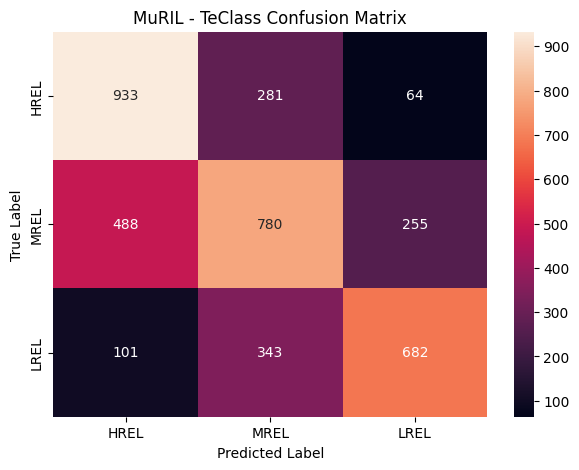

In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Get predictions
predictions = trainer.predict(test_dataset)

predicted_labels = np.argmax(predictions.predictions, axis=1)
true_labels = predictions.label_ids

# Classification report
print("Classification Report:\n")

print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=["HREL", "MREL", "LREL"],
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["HREL", "MREL", "LREL"],
    yticklabels=["HREL", "MREL", "LREL"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MuRIL - TeClass Confusion Matrix")
plt.show()

Check how much of the data is being truncated

In [25]:
# Check token lengths before truncation

sample_texts = train_df.sample(1000, random_state=42)

token_lengths = []

for article, headline in zip(
    sample_texts["article"],
    sample_texts["headline"]
):
    tokens = tokenizer(
        str(article),
        str(headline),
        truncation=False
    )

    token_lengths.append(len(tokens["input_ids"]))

token_lengths = np.array(token_lengths)

print("Number of samples checked:", len(token_lengths))
print("Minimum tokens:", token_lengths.min())
print("Maximum tokens:", token_lengths.max())
print("Average tokens:", token_lengths.mean())
print("Median tokens:", np.median(token_lengths))

print("\nPercentage exceeding 512 tokens:",
      (token_lengths > 512).mean() * 100)

Number of samples checked: 1000
Minimum tokens: 91
Maximum tokens: 466
Average tokens: 234.722
Median tokens: 233.0

Percentage exceeding 512 tokens: 0.0


Check the article/headline token lengths separately

In [26]:
# Check article and headline lengths separately

sample_texts = train_df.sample(1000, random_state=42)

article_lengths = []
headline_lengths = []

for article, headline in zip(
    sample_texts["article"],
    sample_texts["headline"]
):
    article_tokens = tokenizer(
        str(article),
        truncation=False
    )["input_ids"]

    headline_tokens = tokenizer(
        str(headline),
        truncation=False
    )["input_ids"]

    article_lengths.append(len(article_tokens))
    headline_lengths.append(len(headline_tokens))

article_lengths = np.array(article_lengths)
headline_lengths = np.array(headline_lengths)

print("ARTICLE")
print("Average tokens:", article_lengths.mean())
print("Median tokens:", np.median(article_lengths))
print("Maximum tokens:", article_lengths.max())

print("\nHEADLINE")
print("Average tokens:", headline_lengths.mean())
print("Median tokens:", np.median(headline_lengths))
print("Maximum tokens:", headline_lengths.max())

ARTICLE
Average tokens: 222.204
Median tokens: 221.0
Maximum tokens: 450

HEADLINE
Average tokens: 13.518
Median tokens: 13.0
Maximum tokens: 34


Save the trained MuRIL baseline

In [27]:
# Save the trained model and tokenizer

save_path = "./muril_teclass_baseline"

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved successfully!")
print("Saved at:", save_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!
Saved at: ./muril_teclass_baseline


Generate final evaluation table

In [28]:
# Create a clean evaluation summary

report = classification_report(
    true_labels,
    predicted_labels,
    target_names=["HREL", "MREL", "LREL"],
    output_dict=True
)

results_table = pd.DataFrame({
    "Class": ["HREL", "MREL", "LREL", "Weighted Average"],
    "Precision": [
        report["HREL"]["precision"],
        report["MREL"]["precision"],
        report["LREL"]["precision"],
        report["weighted avg"]["precision"]
    ],
    "Recall": [
        report["HREL"]["recall"],
        report["MREL"]["recall"],
        report["LREL"]["recall"],
        report["weighted avg"]["recall"]
    ],
    "F1-Score": [
        report["HREL"]["f1-score"],
        report["MREL"]["f1-score"],
        report["LREL"]["f1-score"],
        report["weighted avg"]["f1-score"]
    ]
})

results_table = results_table.round(4)

display(results_table)

,Class,Precision,Recall,F1-Score
0,HREL,0.6130,0.7300,0.6664
1,MREL,0.5556,0.5121,0.5330
2,LREL,0.6813,0.6057,0.6413
3,Weighted Average,0.6103,0.6099,0.6075


Calculate class weights

In [29]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

print("Class weights:")
print("HREL:", class_weights[0].item())
print("MREL:", class_weights[1].item())
print("LREL:", class_weights[2].item())

Class weights:
HREL: 1.0244884490966797
MREL: 0.8596763014793396
LREL: 1.1618794202804565


Create a weighted-loss MuRIL trainer

In [30]:
import torch
from transformers import Trainer

class WeightedTrainer(Trainer):
    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs.pop("labels")

        outputs = model(**inputs)
        logits = outputs.logits

        loss_fct = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


weighted_trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics
)

print("Weighted-loss Trainer created successfully!")

Weighted-loss Trainer created successfully!


Load a fresh MuRIL model

In [31]:
from transformers import AutoModelForSequenceClassification

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("Fresh MuRIL model loaded for weighted-loss training!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

Fresh MuRIL model loaded for weighted-loss training!


Create the weighted-loss Trainer

In [32]:
weighted_training_args = TrainingArguments(
    output_dir="./muril_teclass_weighted",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    report_to="none"
)

weighted_trainer = WeightedTrainer(
    model=weighted_model,
    args=weighted_training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics
)

print("Weighted-loss Trainer ready!")

Weighted-loss Trainer ready!


Train the weighted model

In [33]:
print("Starting weighted-loss MuRIL training...")

weighted_train_result = weighted_trainer.train()

print("\nWeighted training completed!")

Starting weighted-loss MuRIL training...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.098527,1.098634,0.325185,0.105745,0.325185,0.159593
2,1.096854,1.084409,0.415330,0.341418,0.415330,0.310819
3,0.973635,0.997840,0.472880,0.464200,0.472880,0.430370


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Weighted training completed!


Evaluate the weighted model

In [34]:
weighted_test_results = weighted_trainer.evaluate(test_dataset)

print("Weighted MuRIL Test Results:")
print(weighted_test_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.973635,0.995732,3,0.470843,0.460028,0.470843,0.423906


Weighted MuRIL Test Results:
{'eval_loss': 0.9957315325737, 'eval_accuracy': 0.4708428826075885, 'eval_precision': 0.4600280817913368, 'eval_recall': 0.4708428826075885, 'eval_f1': 0.42390552503757223}


Get the weighted classification report

In [35]:
weighted_predictions = weighted_trainer.predict(test_dataset)

weighted_pred_labels = np.argmax(
    weighted_predictions.predictions,
    axis=1
)

print(classification_report(
    test_df["label"],
    weighted_pred_labels,
    target_names=["HREL", "MREL", "LREL"],
    digits=4
))

              precision    recall  f1-score   support

        HREL     0.5318    0.6142    0.5701      1278
        MREL     0.4155    0.1339    0.2026      1523
        LREL     0.4388    0.7638    0.5574      1126

    accuracy                         0.4708      3927
   macro avg     0.4620    0.5040    0.4433      3927
weighted avg     0.4600    0.4708    0.4239      3927



Confusion matrix for weighted model

In [36]:
weighted_cm = confusion_matrix(
    test_df["label"],
    weighted_pred_labels
)

print("Weighted MuRIL Confusion Matrix:")
print(weighted_cm)

Weighted MuRIL Confusion Matrix:
[[785 178 315]
 [534 204 785]
 [157 109 860]]


Compare Baseline vs Weighted MuRIL

In [37]:
comparison = pd.DataFrame({
    "Model": ["Baseline MuRIL", "Weighted MuRIL"],
    "Accuracy": [
        0.609880,
        weighted_test_results["eval_accuracy"]
    ],
    "Precision": [
        0.610314,
        weighted_test_results["eval_precision"]
    ],
    "Recall": [
        0.609880,
        weighted_test_results["eval_recall"]
    ],
    "F1": [
        0.607458,
        weighted_test_results["eval_f1"]
    ]
})

print(comparison)

            Model  Accuracy  Precision    Recall        F1
0  Baseline MuRIL  0.609880   0.610314  0.609880  0.607458
1  Weighted MuRIL  0.470843   0.460028  0.470843  0.423906


Save the final MuRIL model

In [38]:
final_model_path = "./muril_teclass_final"

trainer.save_model(final_model_path)
tokenizer.save_pretrained(final_model_path)

print("Final MuRIL model saved successfully!")
print("Saved at:", final_model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final MuRIL model saved successfully!
Saved at: ./muril_teclass_final
